# Random Forest for Internet-Advertisement Classification

This notebook trains a Random Forest to decide whether an image on a web page is an
advertisement, the way an ad blocker would. Because a false positive means real
(non-ad) content is blocked, we optimise **precision on the ad class** while keeping
the false-positive rate below a stated limit.

The full honest-evaluation cycle is followed here:

1. **Leak-free split first.** A 60/20/20 stratified train/validation/test split is taken
   *before* any imputer or scaler is fitted.
2. **Leak-free preprocessing.** A `ColumnTransformer` imputes and **scales only the
   three continuous columns** (height, width, aspect ratio); the 1555 binary columns
   are imputed only (most-frequent) and left unscaled.
3. **Baseline.** A `DummyClassifier` (stratified) is reported alongside the model so
   we can show the forest beats a trivial baseline.
4. **5-fold stratified cross-validation.** CV precision and recall are reported as
   mean ± SD on the training data.
5. **Hyperparameter tuning.** `GridSearchCV` selects `n_estimators`, `max_depth` and
   `min_samples_leaf` using 5-fold CV on the training data.
6. **Threshold selection.** A decision threshold that keeps validation FPR ≤ 5% is
   chosen (maximising recall, with precision as a tie-break).
7. **Test set used once, at the end.**

Class encoding: `ad` → 1 (positive), `nonad` → 0.

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
MAX_FALSE_POSITIVE_RATE = 0.05
CONTINUOUS_FEATURES = ["height", "width", "aratio"]

## 1. Load data and encode the target

Duplicates are removed (the EDA showed 856 duplicate rows) so the same rows do not appear in both train and test. The label is encoded as `ad=1`, `nonad=0` so that precision/recall treat the ad class as positive by default.

In [2]:
candidates = [
    Path.cwd() / "ml" / "dataset" / "ad.data",
    Path.cwd() / "dataset" / "ad.data",
]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find ad.data")

df = pd.read_csv(dataset_path, header=None, skipinitialspace=True, na_values="?")
df = df.drop_duplicates().reset_index(drop=True)

X = df.iloc[:, :-1].copy()
# Name columns: first three are continuous, the rest are 0/1 binary features.
X.columns = CONTINUOUS_FEATURES + [f"binary_{i}" for i in range(1, X.shape[1] - 2)]
y = (df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")
     .map({"nonad": 0, "ad": 1}).astype("int8"))

print(f"Dataset shape after duplicate removal: {df.shape}")
print("Class distribution (ad=1, nonad=0):")
print(y.value_counts().sort_index())

Dataset shape after duplicate removal: (2423, 1559)
Class distribution (ad=1, nonad=0):
1558
0    2037
1     386
Name: count, dtype: int64


## 2. Leak-free train/validation/test split

The split is taken **before** any imputation or scaling so no statistics from the validation or test set leak into training. Sizes: 60% train / 20% validation / 20% test.

In [3]:
# Hold out the test set first (20%).
X_fit, X_test, y_fit, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# From the remaining 80%, use 25% as a validation set -> 20% of the total.
X_train, X_validation, y_train, y_validation = train_test_split(
    X_fit, y_fit, test_size=0.25, random_state=RANDOM_STATE, stratify=y_fit
)

print(f"Training rows:   {len(X_train)}")
print(f"Validation rows: {len(X_validation)}")
print(f"Test rows:       {len(X_test)}")

Training rows:   1453
Validation rows: 485
Test rows:       485


## 3. Leak-free preprocessing inside a Pipeline

A `ColumnTransformer` applies different preprocessing to the two feature groups:

* **continuous** (height, width, aratio): `SimpleImputer(strategy="mean")` then `StandardScaler()` — these are the only columns scaled, per the brief.
* **binary** (1555 columns): `SimpleImputer(strategy="most_frequent")` only, left unscaled.

The imputer and scaler live inside the pipeline, so they are fitted on the training fold only — even during cross-validation.

In [4]:
binary_features = [c for c in X.columns if c not in CONTINUOUS_FEATURES]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            Pipeline([
                ("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
            ]),
            CONTINUOUS_FEATURES,
        ),
        (
            "binary",
            SimpleImputer(strategy="most_frequent"),
            binary_features,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name

## 4. Baseline (DummyClassifier)

A stratified `DummyClassifier` makes random predictions respecting the class prior. It defines the floor a real model must beat. We report 5-fold stratified CV precision and recall as mean ± SD on the training data.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["precision", "recall"]

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
])

baseline_cv = cross_validate(
    baseline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
)
print("Baseline — DummyClassifier (stratified), 5-fold CV (mean ± SD):")
print(f"  Precision (ad): {baseline_cv['test_precision'].mean():.4f} ± "
      f"{baseline_cv['test_precision'].std():.4f}")
print(f"  Recall    (ad): {baseline_cv['test_recall'].mean():.4f} ± "
      f"{baseline_cv['test_recall'].std():.4f}")

Baseline — DummyClassifier (stratified), 5-fold CV (mean ± SD):
  Precision (ad): 0.1347 ± 0.0666
  Recall    (ad): 0.1417 ± 0.0692


## 5. Random Forest — 5-fold CV with default hyperparameters

Before tuning, the Random Forest is evaluated with 5-fold stratified CV on the training data, again reported as mean ± SD. `class_weight="balanced"` addresses the class imbalance (~16% ads).

In [6]:
rf_default = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=None,  # single-threaded: let cross_validate/GridSearchCV parallelise the folds
    )),
])

rf_cv = cross_validate(
    rf_default, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
)
print("Random Forest (default) — 5-fold CV (mean ± SD):")
print(f"  Precision (ad): {rf_cv['test_precision'].mean():.4f} ± "
      f"{rf_cv['test_precision'].std():.4f}")
print(f"  Recall    (ad): {rf_cv['test_recall'].mean():.4f} ± "
      f"{rf_cv['test_recall'].std():.4f}")

Random Forest (default) — 5-fold CV (mean ± SD):
  Precision (ad): 0.9101 ± 0.0364
  Recall    (ad): 0.8493 ± 0.0659


## 6. Hyperparameter tuning with GridSearchCV

`GridSearchCV` searches over `n_estimators`, `max_depth` and `min_samples_leaf`, using the same 5-fold stratified CV on the **training** data. The best estimator is then refit on the full training set (`refit=True`).

In [7]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20],
    "classifier__min_samples_leaf": [1, 4],
}

grid = GridSearchCV(
    rf_default,
    param_grid,
    cv=cv,
    scoring=scoring,
    refit="precision",
    n_jobs=-1,
    return_train_score=False,
)

t0 = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f"Grid search over {len(grid.cv_results_['params'])} param combos "
      f"× {cv.get_n_splits()} folds (training time: {grid_time:.1f}s)")
print("Best parameters:", grid.best_params_)

best_idx = grid.best_index_
print(f"Best CV precision (mean ± SD): "
      f"{grid.cv_results_['mean_test_precision'][best_idx]:.4f} ± "
      f"{grid.cv_results_['std_test_precision'][best_idx]:.4f}")
print(f"Recall at that point     (mean ± SD): "
      f"{grid.cv_results_['mean_test_recall'][best_idx]:.4f} ± "
      f"{grid.cv_results_['std_test_recall'][best_idx]:.4f}")

Grid search over 8 param combos × 5 folds (training time: 6.5s)
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Best CV precision (mean ± SD): 0.9559 ± 0.0162
Recall at that point     (mean ± SD): 0.8318 ± 0.0599


## 7. Threshold selection on the validation set

The tuned model (already refit on the full training set) outputs probabilities. Following the chosen metric — **precision on the ad class**, since blocking real content is the worse mistake — we keep the validation false-positive rate **≤ 5%** and then **maximise precision**, subject to a recall floor of 0.50 so the threshold cannot collapse to predicting almost nothing as an ad. If no threshold meets the recall floor under the FPR cap, we fall back to the FPR-eligible threshold with the highest recall. This mirrors the threshold logic used in the SVM notebook.

In [8]:
best_model = grid.best_estimator_
ad_index = list(best_model.classes_).index(1)

validation_ad_proba = best_model.predict_proba(X_validation)[:, ad_index]
nonad_count = int((y_validation == 0).sum())
MIN_VALIDATION_RECALL = 0.50

candidate_thresholds = np.unique(np.concatenate((
    np.array([0.0]),
    validation_ad_proba,
)))

# Every threshold keeping the validation FPR under the stated limit.
fpr_eligible = []
for threshold in candidate_thresholds:
    predicted_ad = (validation_ad_proba >= threshold).astype(int)
    false_positives = int(((predicted_ad == 1) & (y_validation == 0)).sum())
    fpr = false_positives / nonad_count
    if fpr <= MAX_FALSE_POSITIVE_RATE:
        p = precision_score(y_validation, predicted_ad, zero_division=0)
        r = recall_score(y_validation, predicted_ad, zero_division=0)
        fpr_eligible.append((threshold, fpr, p, r))

if not fpr_eligible:
    raise RuntimeError("No threshold satisfies the validation false-positive limit")

# Prefer thresholds that also meet the recall floor; there, maximise precision.
eligible = [row for row in fpr_eligible if row[3] >= MIN_VALIDATION_RECALL]
if eligible:
    threshold, val_fpr, val_precision, val_recall = max(
        eligible, key=lambda row: (row[2], row[3], row[0])
    )
    print(f"Selected threshold: {threshold:.6f}")
    print(f"Validation false-positive-rate limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
    print(f"Validation false-positive rate: {val_fpr:.3%}")
    print(f"Validation ad precision: {val_precision:.4f}")
    print(f"Validation ad recall:    {val_recall:.4f}")
    print(f"Recall floor: {MIN_VALIDATION_RECALL:.2f} (met)")
else:
    # Fall back: keep the FPR guarantee, take the threshold with highest recall.
    threshold, val_fpr, val_precision, val_recall = max(
        fpr_eligible, key=lambda row: (row[3], row[2], row[0])
    )
    print(f"Selected threshold: {threshold:.6f}")
    print(f"Validation false-positive-rate limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
    print(f"Validation false-positive rate: {val_fpr:.3%}")
    print(f"Validation ad precision: {val_precision:.4f}")
    print(f"Validation ad recall:    {val_recall:.4f}")
    print(f"Warning: recall floor {MIN_VALIDATION_RECALL:.2f} not attainable under "
          f"the FPR cap; selected highest-recall FPR-eligible threshold.")

Selected threshold: 0.581607
Validation false-positive-rate limit: <= 5.0%
Validation false-positive rate: 0.245%
Validation ad precision: 0.9844
Validation ad recall:    0.8182
Recall floor: 0.50 (met)


## 8. Final evaluation on the held-out test set

The test set is used **once**, here, with the threshold chosen above.

False-positive limit: <= 5.0%
Test false positives: 1 / 408
Test false-positive rate: 0.245%
Test ad precision: 0.9828
Test ad recall:    0.7403
Test ad F1-score:  0.8444
Test accuracy:     0.9567

Classification report (ad = positive class):
              precision    recall  f1-score   support

       nonad       0.95      1.00      0.97       408
          ad       0.98      0.74      0.84        77

    accuracy                           0.96       485
   macro avg       0.97      0.87      0.91       485
weighted avg       0.96      0.96      0.95       485



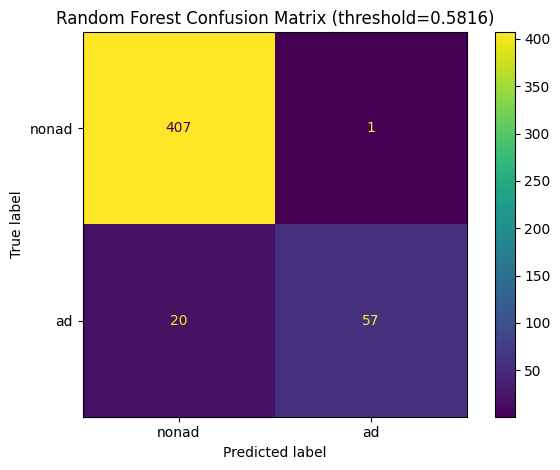

In [9]:
test_ad_proba = best_model.predict_proba(X_test)[:, ad_index]
y_pred = (test_ad_proba >= threshold).astype(int)

test_false_positives = int(((y_pred == 1) & (y_test == 0)).sum())
test_nonad_count = int((y_test == 0).sum())
test_fpr = test_false_positives / test_nonad_count

print(f"False-positive limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Test false positives: {test_false_positives} / {test_nonad_count}")
print(f"Test false-positive rate: {test_fpr:.3%}")
print(f"Test ad precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test ad recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test ad F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test accuracy:     {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification report (ad = positive class):")
print(classification_report(y_test, y_pred, target_names=["nonad", "ad"],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["nonad", "ad"],
)
plt.title(f"Random Forest Confusion Matrix (threshold={threshold:.4f})")
plt.tight_layout()
plt.show()

## 9. Feature importance — interpretation

Random Forest `feature_importances_` (mean decrease in impurity) shows which features drive the ad decision. Names come from the fitted `ColumnTransformer`.

Top 20 features by importance (names from ad.names):


,importance
width,0.086516
aratio,0.060891
ancurl*com,0.056410
ancurl*click,0.029078
alt*click,0.028490
ancurl*http+www,0.027150
url*ads,0.025342
height,0.025064
alt*click+here,0.022868
alt*here,0.021685


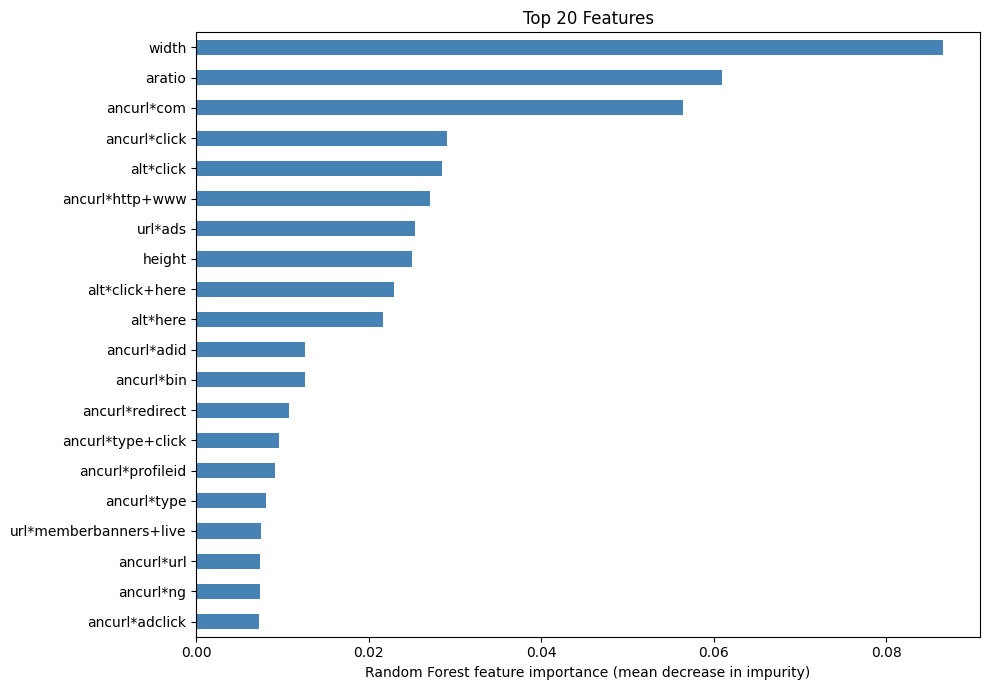

In [10]:
classifier = best_model.named_steps["classifier"]
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(classifier.feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False)

# Map the generic binary_N labels to the real token names listed in ad.names
# (the same parsing used in the EDA notebook), so the interpretation is verifiable.
import re
display_names = {c: c for c in importance.index}
for p in [Path.cwd() / "ml" / "dataset" / "ad.names",
          Path.cwd() / "dataset" / "ad.names"]:
    if p.exists():
        attr = []
        for line in p.read_text(encoding="latin-1").splitlines():
            m = re.match(r"^\s*(.+?):\s*(?:continuous|0,1)\.", line)
            if m:
                attr.append(m.group(1).strip())
        if len(attr) == X.shape[1]:
            display_names = {
                X.columns[j]: (X.columns[j] if X.columns[j] in CONTINUOUS_FEATURES
                               else attr[j])
                for j in range(X.shape[1])
            }
        break

importance_named = importance.copy()
importance_named.index = [display_names.get(c, c) for c in importance.index]

print("Top 20 features by importance (names from ad.names):")
display(importance_named.head(20).to_frame("importance"))

plt.figure(figsize=(10, 7))
importance_named.head(20).sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Random Forest feature importance (mean decrease in impurity)")
plt.title("Top 20 Features")
plt.tight_layout()
plt.show()

## 10. Interpretation and limitations

**Interpretation.** The model leans on two kinds of signal. First, **image
geometry** — `width`, `aratio` and `height` are among the top features, consistent
with 1998 ads being banner images of recognisable, narrow dimensions. Second, a
handful of **URL / anchor-text tokens** dominate the rest: anchor-URL tokens such
as `ancurl*click`, `ancurl*adclick`, `ancurl*adid`, `ancurl*redirect`,
`ancurl*profileid` and `ancurl*bin`, alt-text tokens such as `alt*click` and
`alt*click+here`, and URL tokens such as `url*ads` and
`url*memberbanners+live`. These are exactly what an ad blocker would expect —
click-through URLs carrying ad IDs, redirects and profile/binary parameters, and
banner-serving host names. A small number of features do almost all of the work;
the great majority of the 1555 binary columns are never split on. This matches the
domain intuition that the decision can rest on a small, interpretable signal set
rather than the full high-dimensional bag of tokens.

**What this model cannot be trusted to do.**

* **It will not transfer to today's web.** The data is from 1998: ads were static
  banner images with predictable sizes and ad-network URLs. Modern ads are served
  programmatically, are often indistinguishable from content (native ads), are
  injected client-side by scripts, and live behind CDNs whose URLs and tokens
  differ entirely from 1998 ad networks. The token vocabulary here simply does not
  exist on the modern web, so a model that scores well on this set should not be
  trusted on today's pages without retraining on current data.
* **The operating point is fragile.** The precision-focused threshold and its 5%
  false-positive cap were chosen on a small validation split (485 rows); on a
  different population the achieved false-positive rate can drift, so the threshold
  should be re-validated before deployment.
* **Imputation hides missing geometry.** Rows missing height/width/aratio are
  mean-imputed; a row with genuinely unknown dimensions is forced into the geometry
  distribution of the training set, which can mislead the size-based signal.
* **No notion of context.** The model sees a single image in isolation; real ad
  blockers also use page context, network requests and filter lists, none of which
  are in this feature set.